In [2]:

import pandas as pd
import numpy as np

# Create reproducible hypothetical logistics data
np.random.seed(42)

n = 500

df = pd.DataFrame({
    "Shipment_ID": [f"SH{i:04d}" for i in range(1, n + 1)],
    "Order_Date": pd.date_range(
        start="2026-01-01", periods=n, freq="D"
    ),
    "Distance_KM": np.random.randint(10, 501, n),
    "Shipment_Weight_KG": np.round(
        np.random.uniform(1, 100, n), 2
    ),
    "Shipment_Volume": np.random.randint(1, 21, n),
    "Delivery_Time_Days": np.random.randint(1, 9, n),
    "Delivery_Zone": np.random.choice(
        ["North", "South", "East", "West"], n
    ),
    "Delivery_Status": np.random.choice(
        ["Delivered", "Delayed", "Failed"],
        n, p=[0.75, 0.20, 0.05]
    )
})

# Simulate transportation cost
df["Transportation_Cost"] = np.round(
    100 + df["Distance_KM"] * 5
    + df["Shipment_Weight_KG"] * 2
    + np.random.normal(0, 100, n),
    2
)

# Display the first five records
df.head()


,Shipment_ID,Order_Date,Distance_KM,Shipment_Weight_KG,Shipment_Volume,Delivery_Time_Days,Delivery_Zone,Delivery_Status,Transportation_Cost
0,SH0001,2026-01-01,112,85.02,2,6,North,Delivered,783.58
1,SH0002,2026-01-02,445,14.53,10,3,North,Delayed,2374.18
2,SH0003,2026-01-03,358,71.18,5,1,North,Delayed,2060.69
3,SH0004,2026-01-04,280,55.73,10,1,East,Delayed,1585.57
4,SH0005,2026-01-05,116,30.35,1,1,South,Delayed,799.37


In [3]:

df.to_csv("SwiftRoute_Logistics_Dataset.csv", index=False)

print("Dataset created successfully!")
print("Number of shipments:", len(df))
print("Number of columns:", len(df.columns))


Dataset created successfully!
Number of shipments: 500
Number of columns: 9


In [4]:

from google.colab import files
files.download("SwiftRoute_Logistics_Dataset.csv")



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [5]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")


All libraries imported successfully!


In [6]:

# Display the first five rows
display(df.head())

# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Check column names and data types
df.info()

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate records:", df.duplicated().sum())


,Shipment_ID,Order_Date,Distance_KM,Shipment_Weight_KG,Shipment_Volume,Delivery_Time_Days,Delivery_Zone,Delivery_Status,Transportation_Cost
0,SH0001,2026-01-01,112,85.02,2,6,North,Delivered,783.58
1,SH0002,2026-01-02,445,14.53,10,3,North,Delayed,2374.18
2,SH0003,2026-01-03,358,71.18,5,1,North,Delayed,2060.69
3,SH0004,2026-01-04,280,55.73,10,1,East,Delayed,1585.57
4,SH0005,2026-01-05,116,30.35,1,1,South,Delayed,799.37


Dataset shape: (500, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   Shipment_ID          500 non-null    object        
 1   Order_Date           500 non-null    datetime64[ns]
 2   Distance_KM          500 non-null    int64         
 3   Shipment_Weight_KG   500 non-null    float64       
 4   Shipment_Volume      500 non-null    int64         
 5   Delivery_Time_Days   500 non-null    int64         
 6   Delivery_Zone        500 non-null    object        
 7   Delivery_Status      500 non-null    object        
 8   Transportation_Cost  500 non-null    float64       
dtypes: datetime64[ns](1), float64(2), int64(3), object(3)
memory usage: 35.3+ KB

Missing values:
Shipment_ID            0
Order_Date             0
Distance_KM            0
Shipment_Weight_KG     0
Shipment_Volume        0
Delivery_Time_Days   

In [7]:

# Summary statistics for numerical columns
display(df.describe().round(2))

# Central tendency of key logistics metrics
metrics = [
    "Delivery_Time_Days",
    "Distance_KM",
    "Shipment_Weight_KG",
    "Shipment_Volume",
    "Transportation_Cost"
]

summary = pd.DataFrame({
    "Mean": df[metrics].mean(),
    "Median": df[metrics].median(),
    "Standard Deviation": df[metrics].std()
})

display(summary.round(2))


,Order_Date,Distance_KM,Shipment_Weight_KG,Shipment_Volume,Delivery_Time_Days,Transportation_Cost
count,500,500.00,500.00,500.00,500.00,500.00
mean,2026-09-07 12:00:00,259.89,50.71,10.40,4.48,1500.78
min,2026-01-01 00:00:00,11.00,1.26,1.00,1.00,88.06
25%,2026-05-05 18:00:00,142.25,26.01,5.00,3.00,925.23
50%,2026-09-07 12:00:00,261.00,52.08,10.00,4.00,1492.96
75%,2027-01-10 06:00:00,381.25,73.98,15.00,6.00,2102.02
max,2027-05-15 00:00:00,499.00,99.77,20.00,8.00,2820.39
std,NaN,139.43,28.24,5.69,2.25,709.46


,Mean,Median,Standard Deviation
Delivery_Time_Days,4.48,4.00,2.25
Distance_KM,259.89,261.00,139.43
Shipment_Weight_KG,50.71,52.08,28.24
Shipment_Volume,10.40,10.00,5.69
Transportation_Cost,1500.78,1492.96,709.46


In [8]:

summary.to_csv("SwiftRoute_EDA_Summary.csv")
files.download("SwiftRoute_EDA_Summary.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:
from google.colab import files

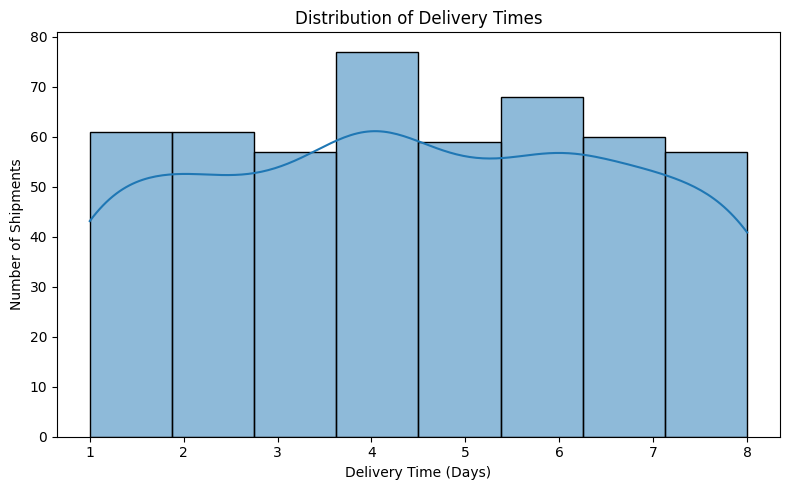

In [12]:
# Delivery Time Distribution

plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Delivery_Time_Days",
    bins=8,
    kde=True
)

plt.title("Distribution of Delivery Times")
plt.xlabel("Delivery Time (Days)")
plt.ylabel("Number of Shipments")
plt.tight_layout()
plt.show()


In [13]:
plt.savefig("Delivery_Time_Distribution.png", dpi=300, bbox_inches="tight")
files.download("Delivery_Time_Distribution.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<Figure size 640x480 with 0 Axes>

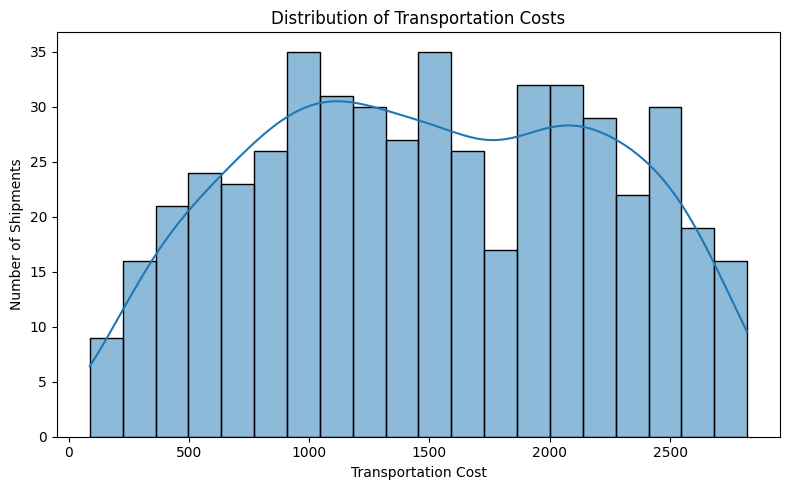

In [14]:
# Transportation Cost Distribution


plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Transportation_Cost",
    bins=20,
    kde=True
)

plt.title("Distribution of Transportation Costs")
plt.xlabel("Transportation Cost")
plt.ylabel("Number of Shipments")
plt.tight_layout()
plt.show()


In [15]:
plt.savefig("Transportation_Cost_Distribution.png", dpi=300, bbox_inches="tight")
files.download("Transportation_Cost_Distribution.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<Figure size 640x480 with 0 Axes>

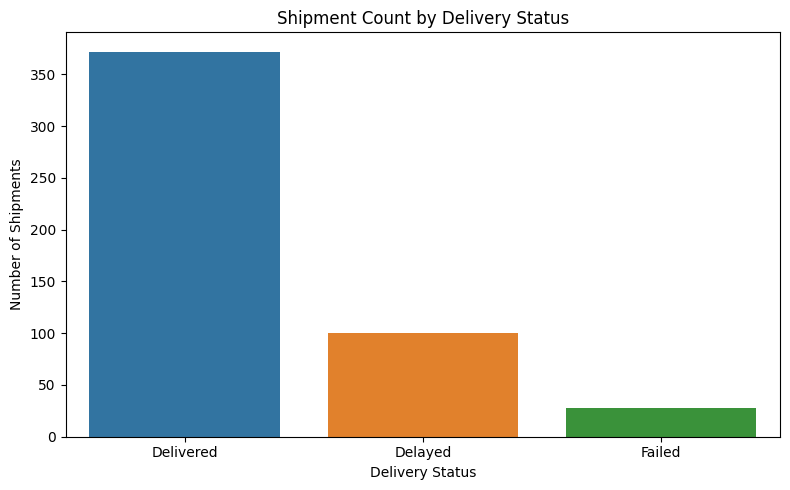

In [16]:
# Delivery Status Analysis



plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Delivery_Status",
    hue="Delivery_Status",
    order=["Delivered", "Delayed", "Failed"],
    legend=False
)

plt.title("Shipment Count by Delivery Status")
plt.xlabel("Delivery Status")
plt.ylabel("Number of Shipments")
plt.tight_layout()

plt.savefig(
    "Delivery_Status_Analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



In [17]:
files.download("Delivery_Status_Analysis.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

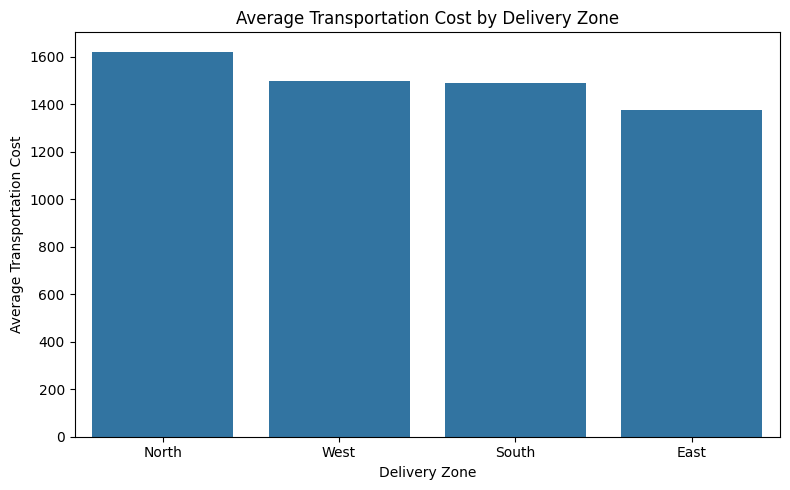

,Transportation_Cost
Delivery_Zone,
North,1621.92
West,1499.71
South,1491.03
East,1375.38


In [18]:
# Average Transportation Cost by Delivery Zone


zone_cost = (
    df.groupby("Delivery_Zone")["Transportation_Cost"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=zone_cost.index,
    y=zone_cost.values
)

plt.title("Average Transportation Cost by Delivery Zone")
plt.xlabel("Delivery Zone")
plt.ylabel("Average Transportation Cost")
plt.tight_layout()

plt.savefig(
    "Cost_by_Delivery_Zone.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

display(zone_cost.round(2))



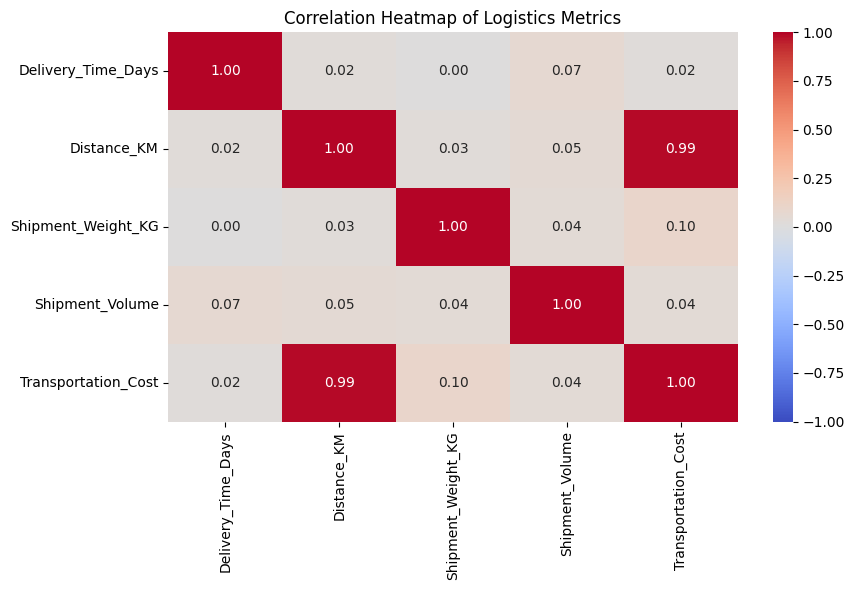

In [19]:
# Correlation Heatmap Logistics Metrics


# Select numerical logistics variables
numeric_df = df[
    [
        "Delivery_Time_Days",
        "Distance_KM",
        "Shipment_Weight_KG",
        "Shipment_Volume",
        "Transportation_Cost"
    ]
]

# Calculate correlations
correlation_matrix = numeric_df.corr()

# Plot the heatmap
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Logistics Metrics")
plt.tight_layout()

# Save the chart before displaying it
plt.savefig(
    "Logistics_Correlation_Heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [20]:
# Delivery Performance KPIs


total_shipments = len(df)

delivered = (df["Delivery_Status"] == "Delivered").sum()
delayed = (df["Delivery_Status"] == "Delayed").sum()
failed = (df["Delivery_Status"] == "Failed").sum()

delivery_success_rate = delivered / total_shipments * 100
delay_rate = delayed / total_shipments * 100
average_cost = df["Transportation_Cost"].mean()

print(f"Total shipments: {total_shipments}")
print(f"Delivered shipments: {delivered}")
print(f"Delayed shipments: {delayed}")
print(f"Failed shipments: {failed}")
print(f"Delivery success rate: {delivery_success_rate:.2f}%")
print(f"Delay rate: {delay_rate:.2f}%")
print(f"Average transportation cost: {average_cost:.2f}")


Total shipments: 500
Delivered shipments: 372
Delayed shipments: 100
Failed shipments: 28
Delivery success rate: 74.40%
Delay rate: 20.00%
Average transportation cost: 1500.78


In [21]:
# Delivery Performance by Zone


# Calculate delivery performance for each zone
zone_performance = df.groupby("Delivery_Zone").agg(
    Total_Shipments=("Shipment_ID", "count"),
    Average_Delivery_Time=("Delivery_Time_Days", "mean"),
    Average_Transportation_Cost=("Transportation_Cost", "mean"),
    Delayed_Shipments=(
        "Delivery_Status",
        lambda x: (x == "Delayed").sum()
    )
)

zone_performance["Delay_Rate_Percent"] = (
    zone_performance["Delayed_Shipments"]
    / zone_performance["Total_Shipments"] * 100
)

display(zone_performance.round(2))


,Total_Shipments,Average_Delivery_Time,Average_Transportation_Cost,Delayed_Shipments,Delay_Rate_Percent
Delivery_Zone,,,,,
East,113,4.75,1375.38,24,21.24
North,129,4.19,1621.92,24,18.60
South,136,4.38,1491.03,29,21.32
West,122,4.66,1499.71,23,18.85


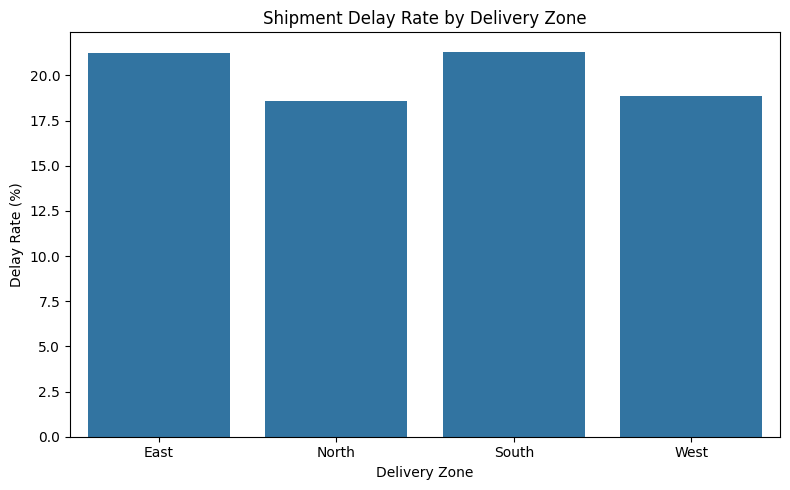

In [22]:
# Delay Rates by Zone


plt.figure(figsize=(8, 5))

sns.barplot(
    data=zone_performance.reset_index(),
    x="Delivery_Zone",
    y="Delay_Rate_Percent"
)

plt.title("Shipment Delay Rate by Delivery Zone")
plt.xlabel("Delivery Zone")
plt.ylabel("Delay Rate (%)")
plt.tight_layout()

plt.savefig(
    "Delay_Rate_by_Zone.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [23]:

files.download("Delay_Rate_by_Zone.png")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>